# ResNet with Tensorgami

*Deep Residual Learning for Image Recognition* (He et al., CVPR 2016) —
[arXiv:1512.03385](https://arxiv.org/abs/1512.03385).

The models come from [`resnet.py`](resnet.py), written as in `torchvision.models.resnet`
(so torchvision is not needed, and its pretrained weights load). A ResNet is a stem
(7×7 convolution and max pooling), four stages `layer1` … `layer4` of residual blocks, and
a classifier. Each block adds its input back to its output: the skip connection.

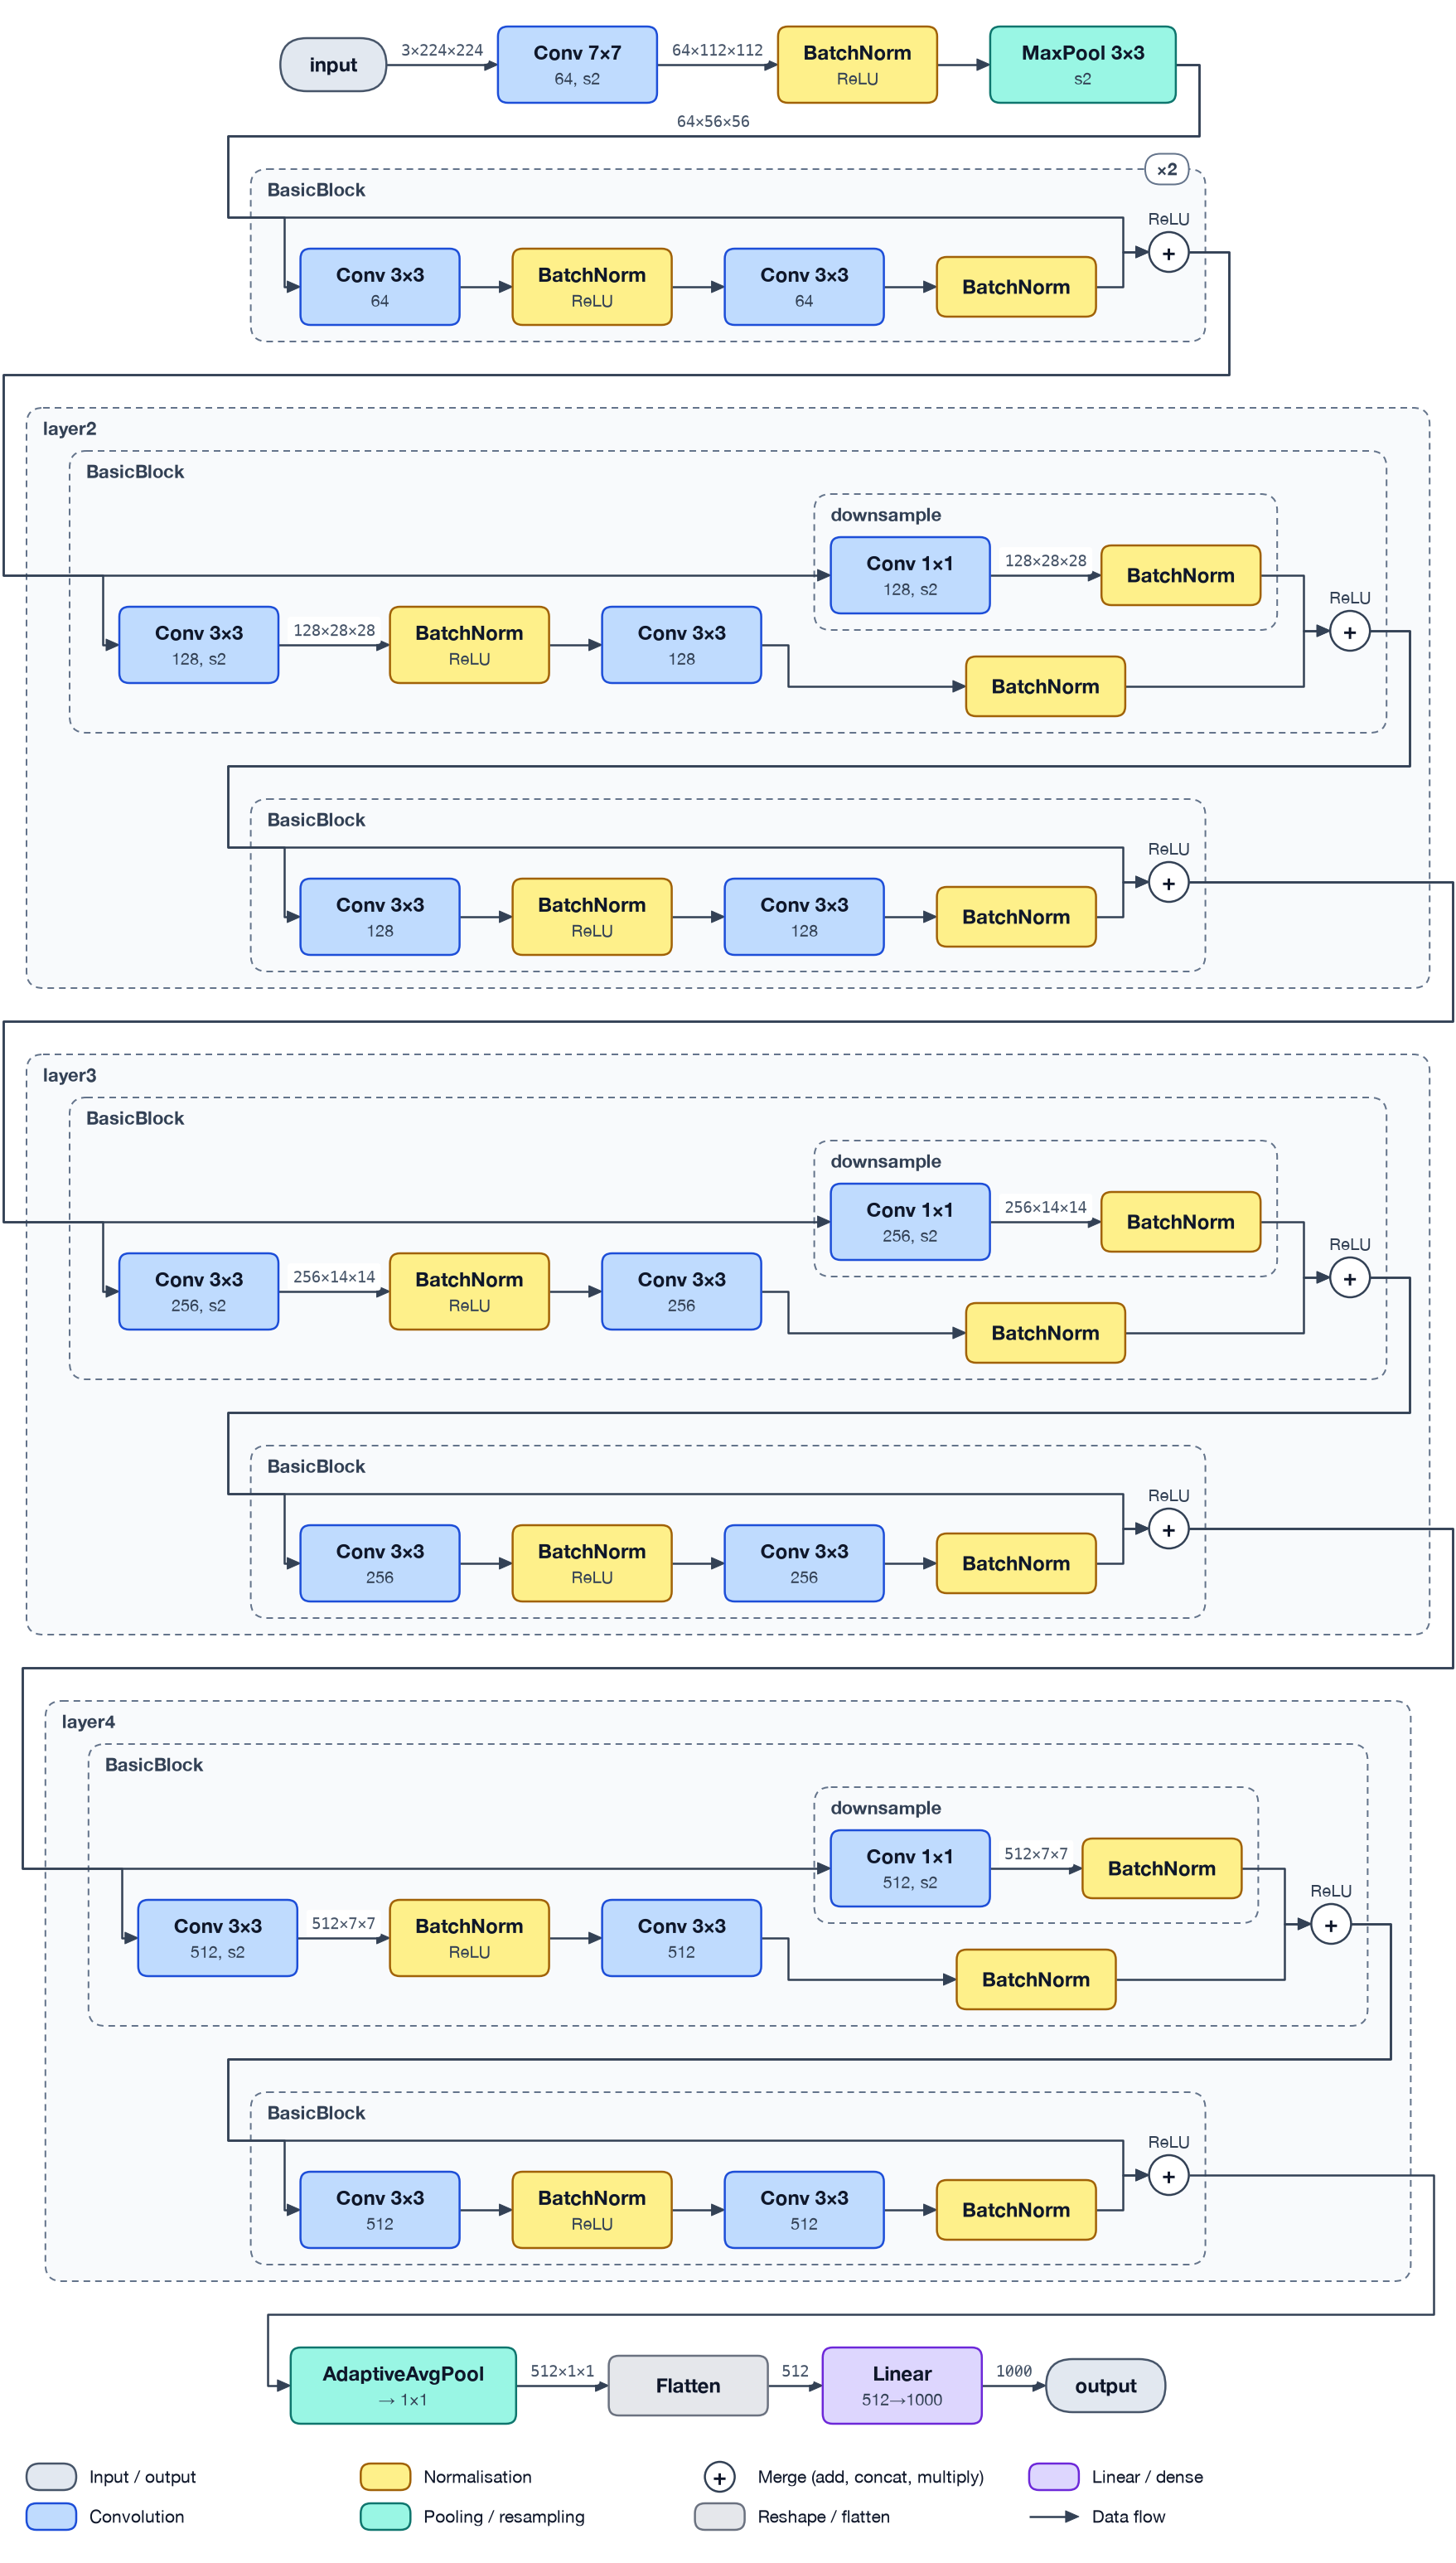

In [1]:
import torch
from resnet import resnet18, resnet34, resnet50  # examples/resnet.py

import tensorgami as tg

model = resnet18()
x = torch.randn(1, 3, 224, 224)  # one image, with the batch dimension

tg.draw(model, x)  # layer level, block view, default style

## Reading the figure

- **Box colour**: what kind of operation it is (the legend below the figure): convolution
  blue, normalisation yellow, activation pink, pooling green, linear purple.
- **Box text**: the layer and its kernel (`Conv 3×3`), then its details: for a convolution the
  number of output channels and the stride if it is not 1 (`128, s2`: 128 channels, stride 2);
  for a pooling layer its stride when it differs from the kernel (`s2`); for a linear layer
  its input → output features (`512→1000`); for adaptive pooling its output size (`→ 1×1`).
  At the layer level, an activation is folded into the layer before it: `BatchNorm` with
  `ReLU` below means batch norm, then ReLU.
- **Numbers on the wires**: the shape of the tensor passed on, channels × height × width,
  without the batch dimension (`64×56×56`), shown where it changes.
- **Frames** (dashed): modules that contain layers, titled with their attribute name (`layer2`,
  `downsample`) or class (`BasicBlock`). A badge such as **×2** on a frame means the block is
  repeated that many times in a row, identically, and drawn once.
- **⊕**: the residual addition; the skip connection runs around the block into it, and the
  `ReLU` beside it is applied after the sum. The first block of `layer2`–`layer4` halves the
  resolution, so its skip goes through `downsample` (a 1×1 convolution with stride 2) to
  match the shape.

## Level of detail

`level` by number or name: 0 `"system"`, 1 `"stages"` (the model's direct sub-modules),
2 `"layers"` (the default), 3 `"operators"` (everything traced).

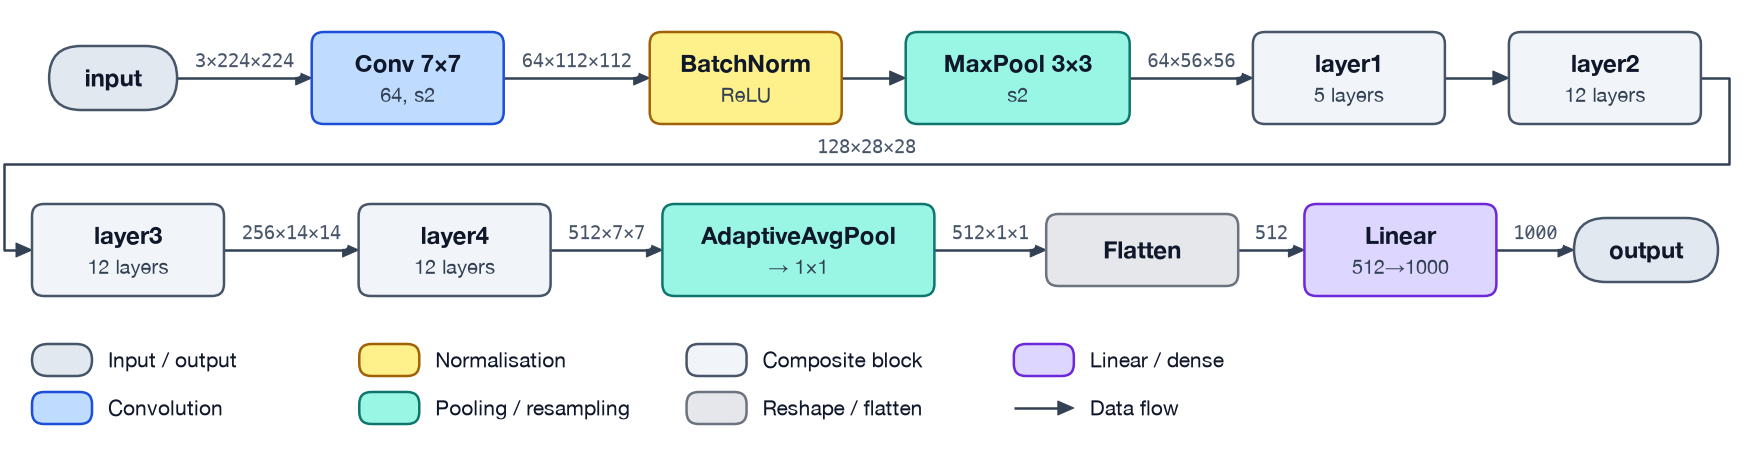

In [2]:
tg.draw(model, x, level="stages")

At the operator level every ReLU is a box of its own, and the figure gets long. A figure
wider than `wrap_width` (1100 px by default) wraps into rows that read like lines of text,
and so does a frame that alone is too wide: here each stage holds its two blocks one above
the other. A row only ends where a single wire continues, so a residual block (its skip
runs alongside) is never split.

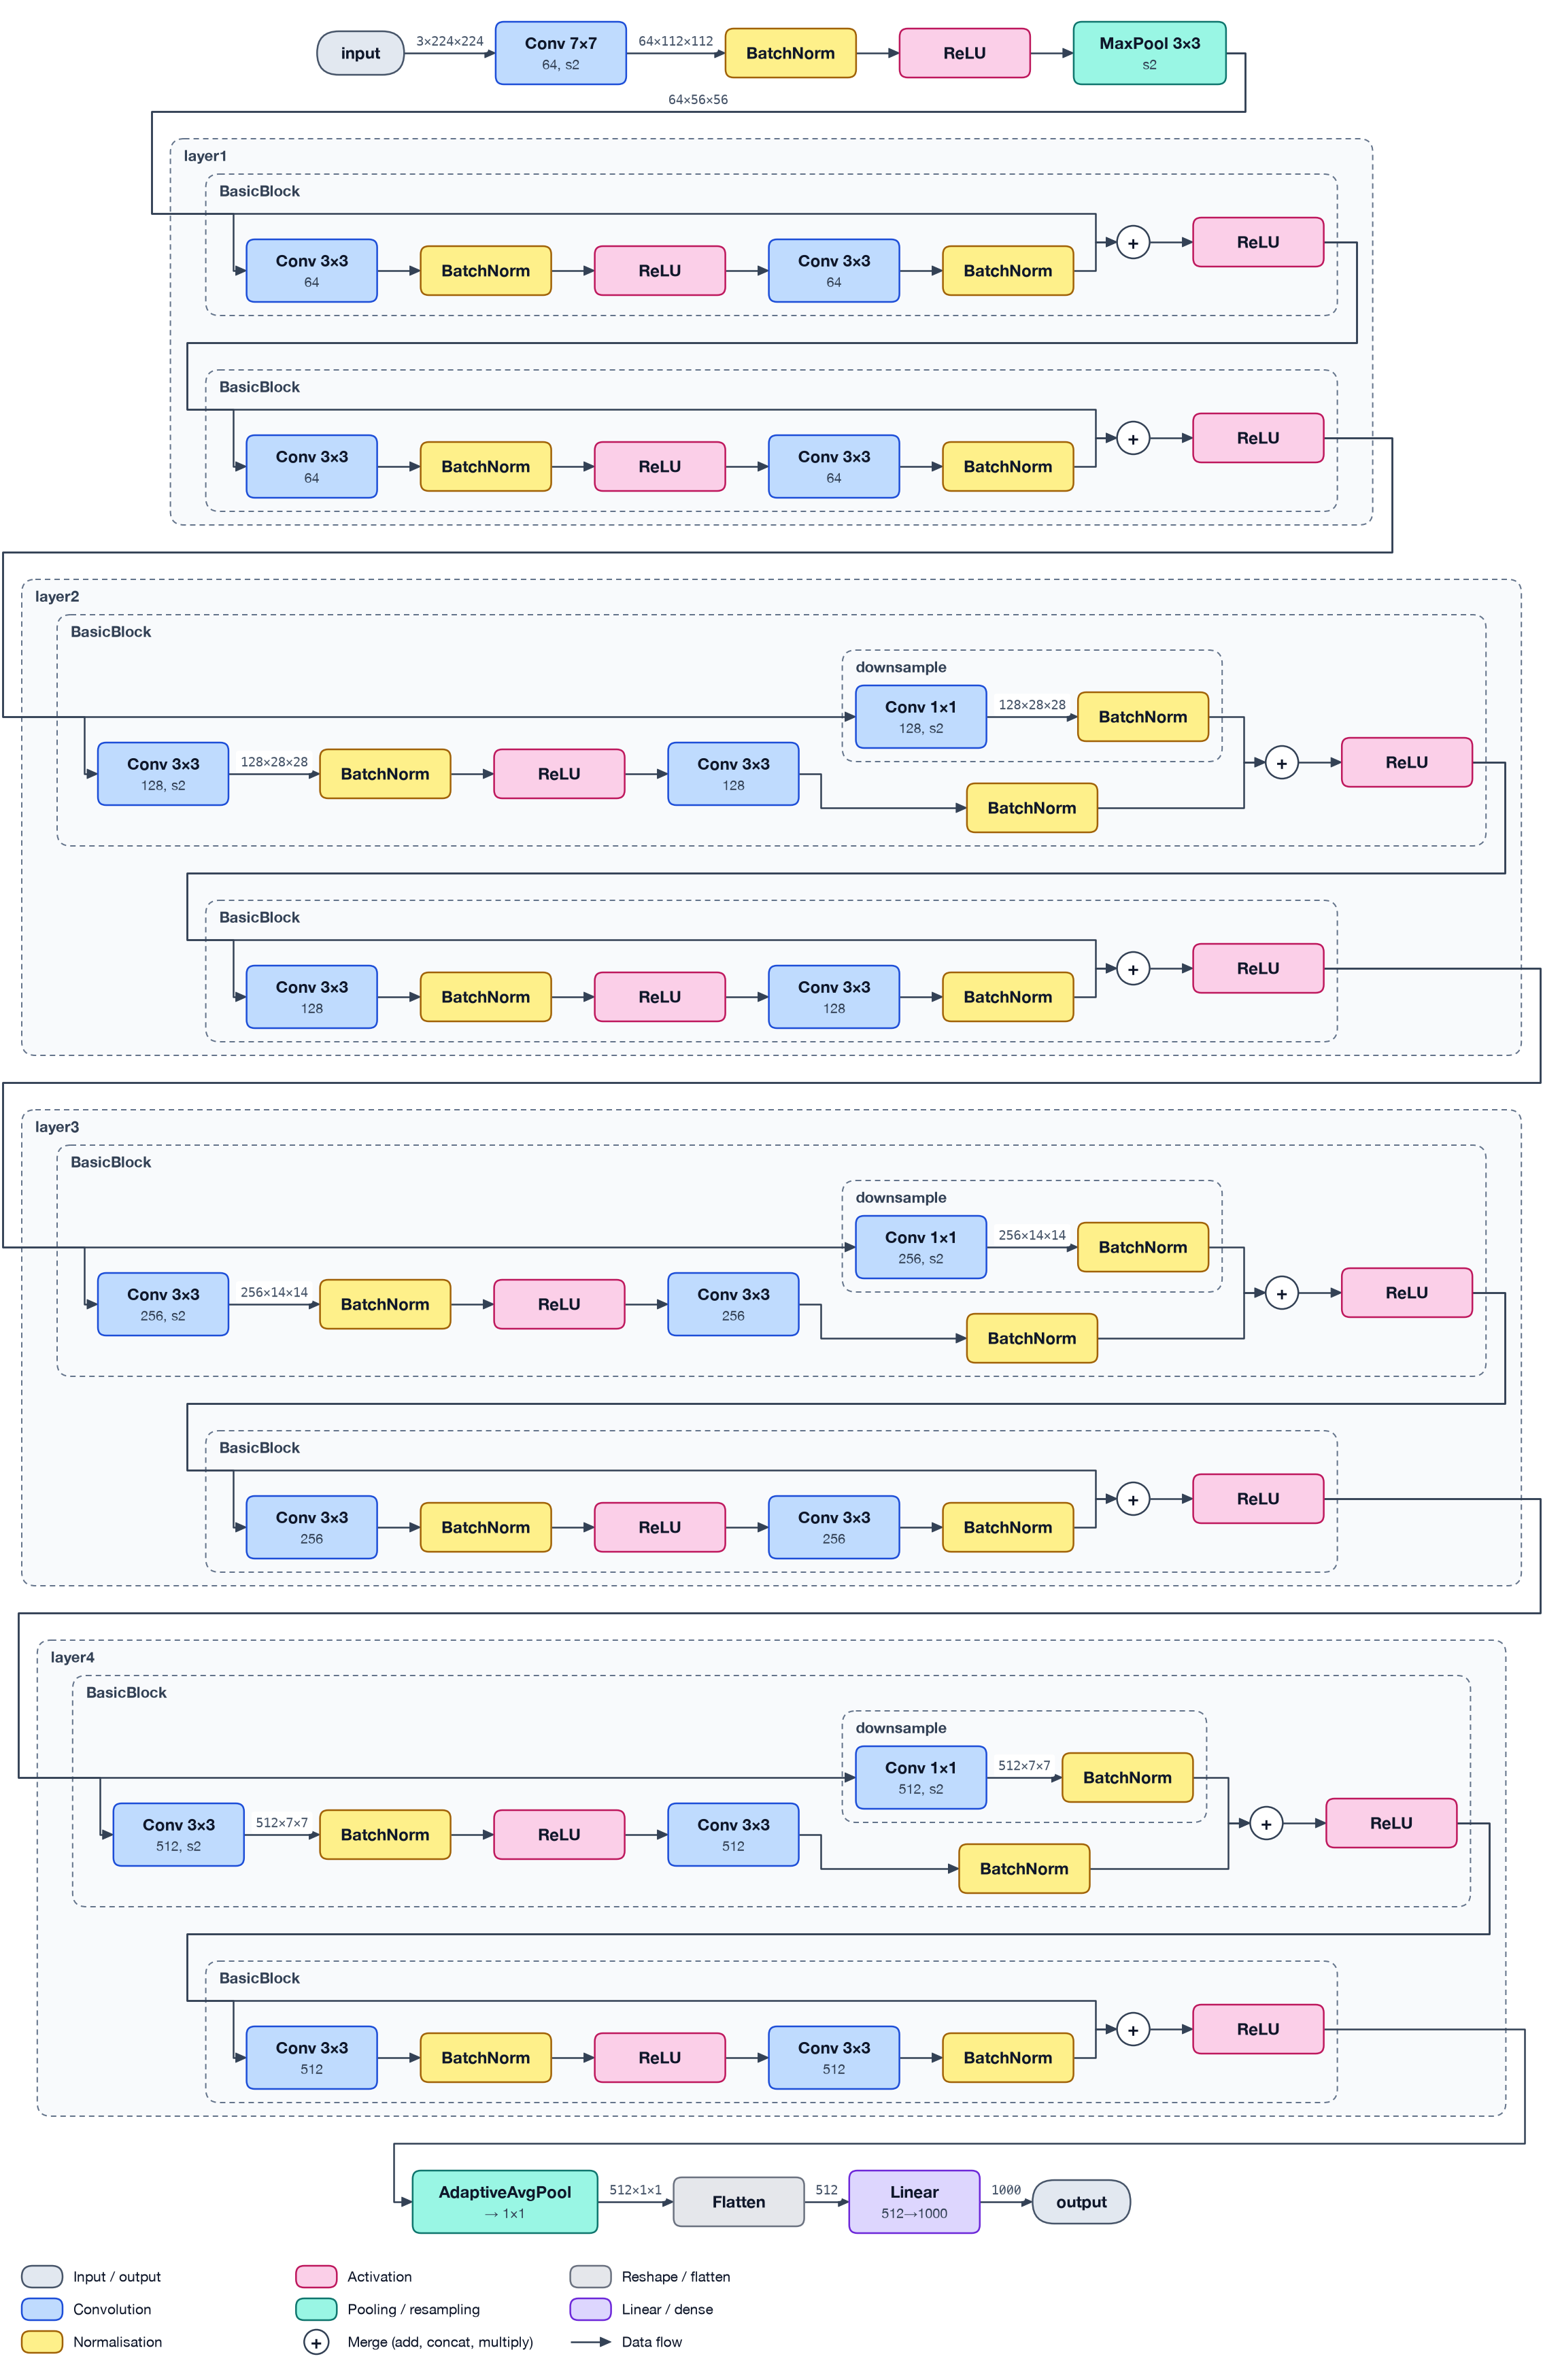

In [3]:
tg.draw(model, x, level="operators")

`wrap_width` sets the width to fold at (a larger value for a wide slide), and
`wrap_width=None` keeps everything on one line.

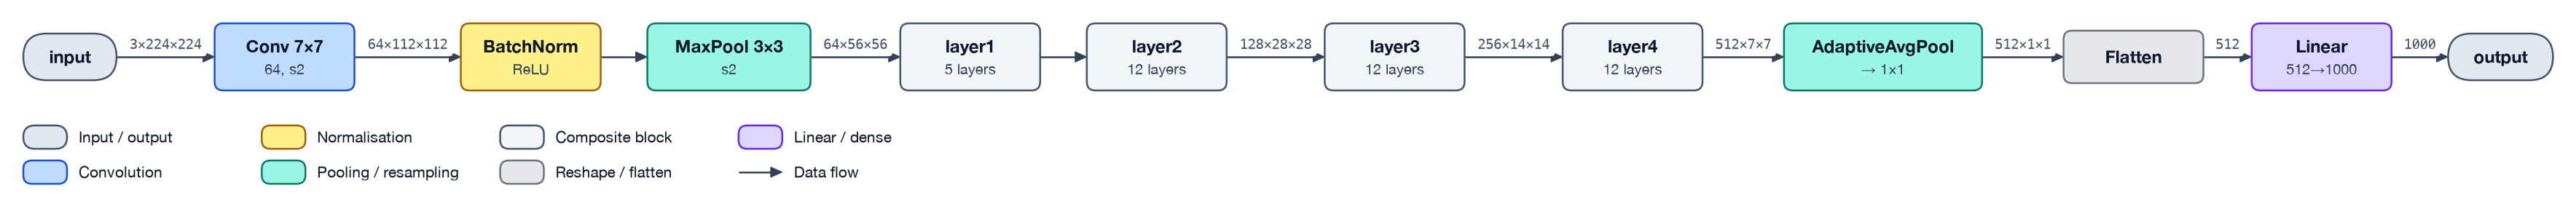

In [4]:
tg.draw(model, x, level="stages", wrap_width=None)

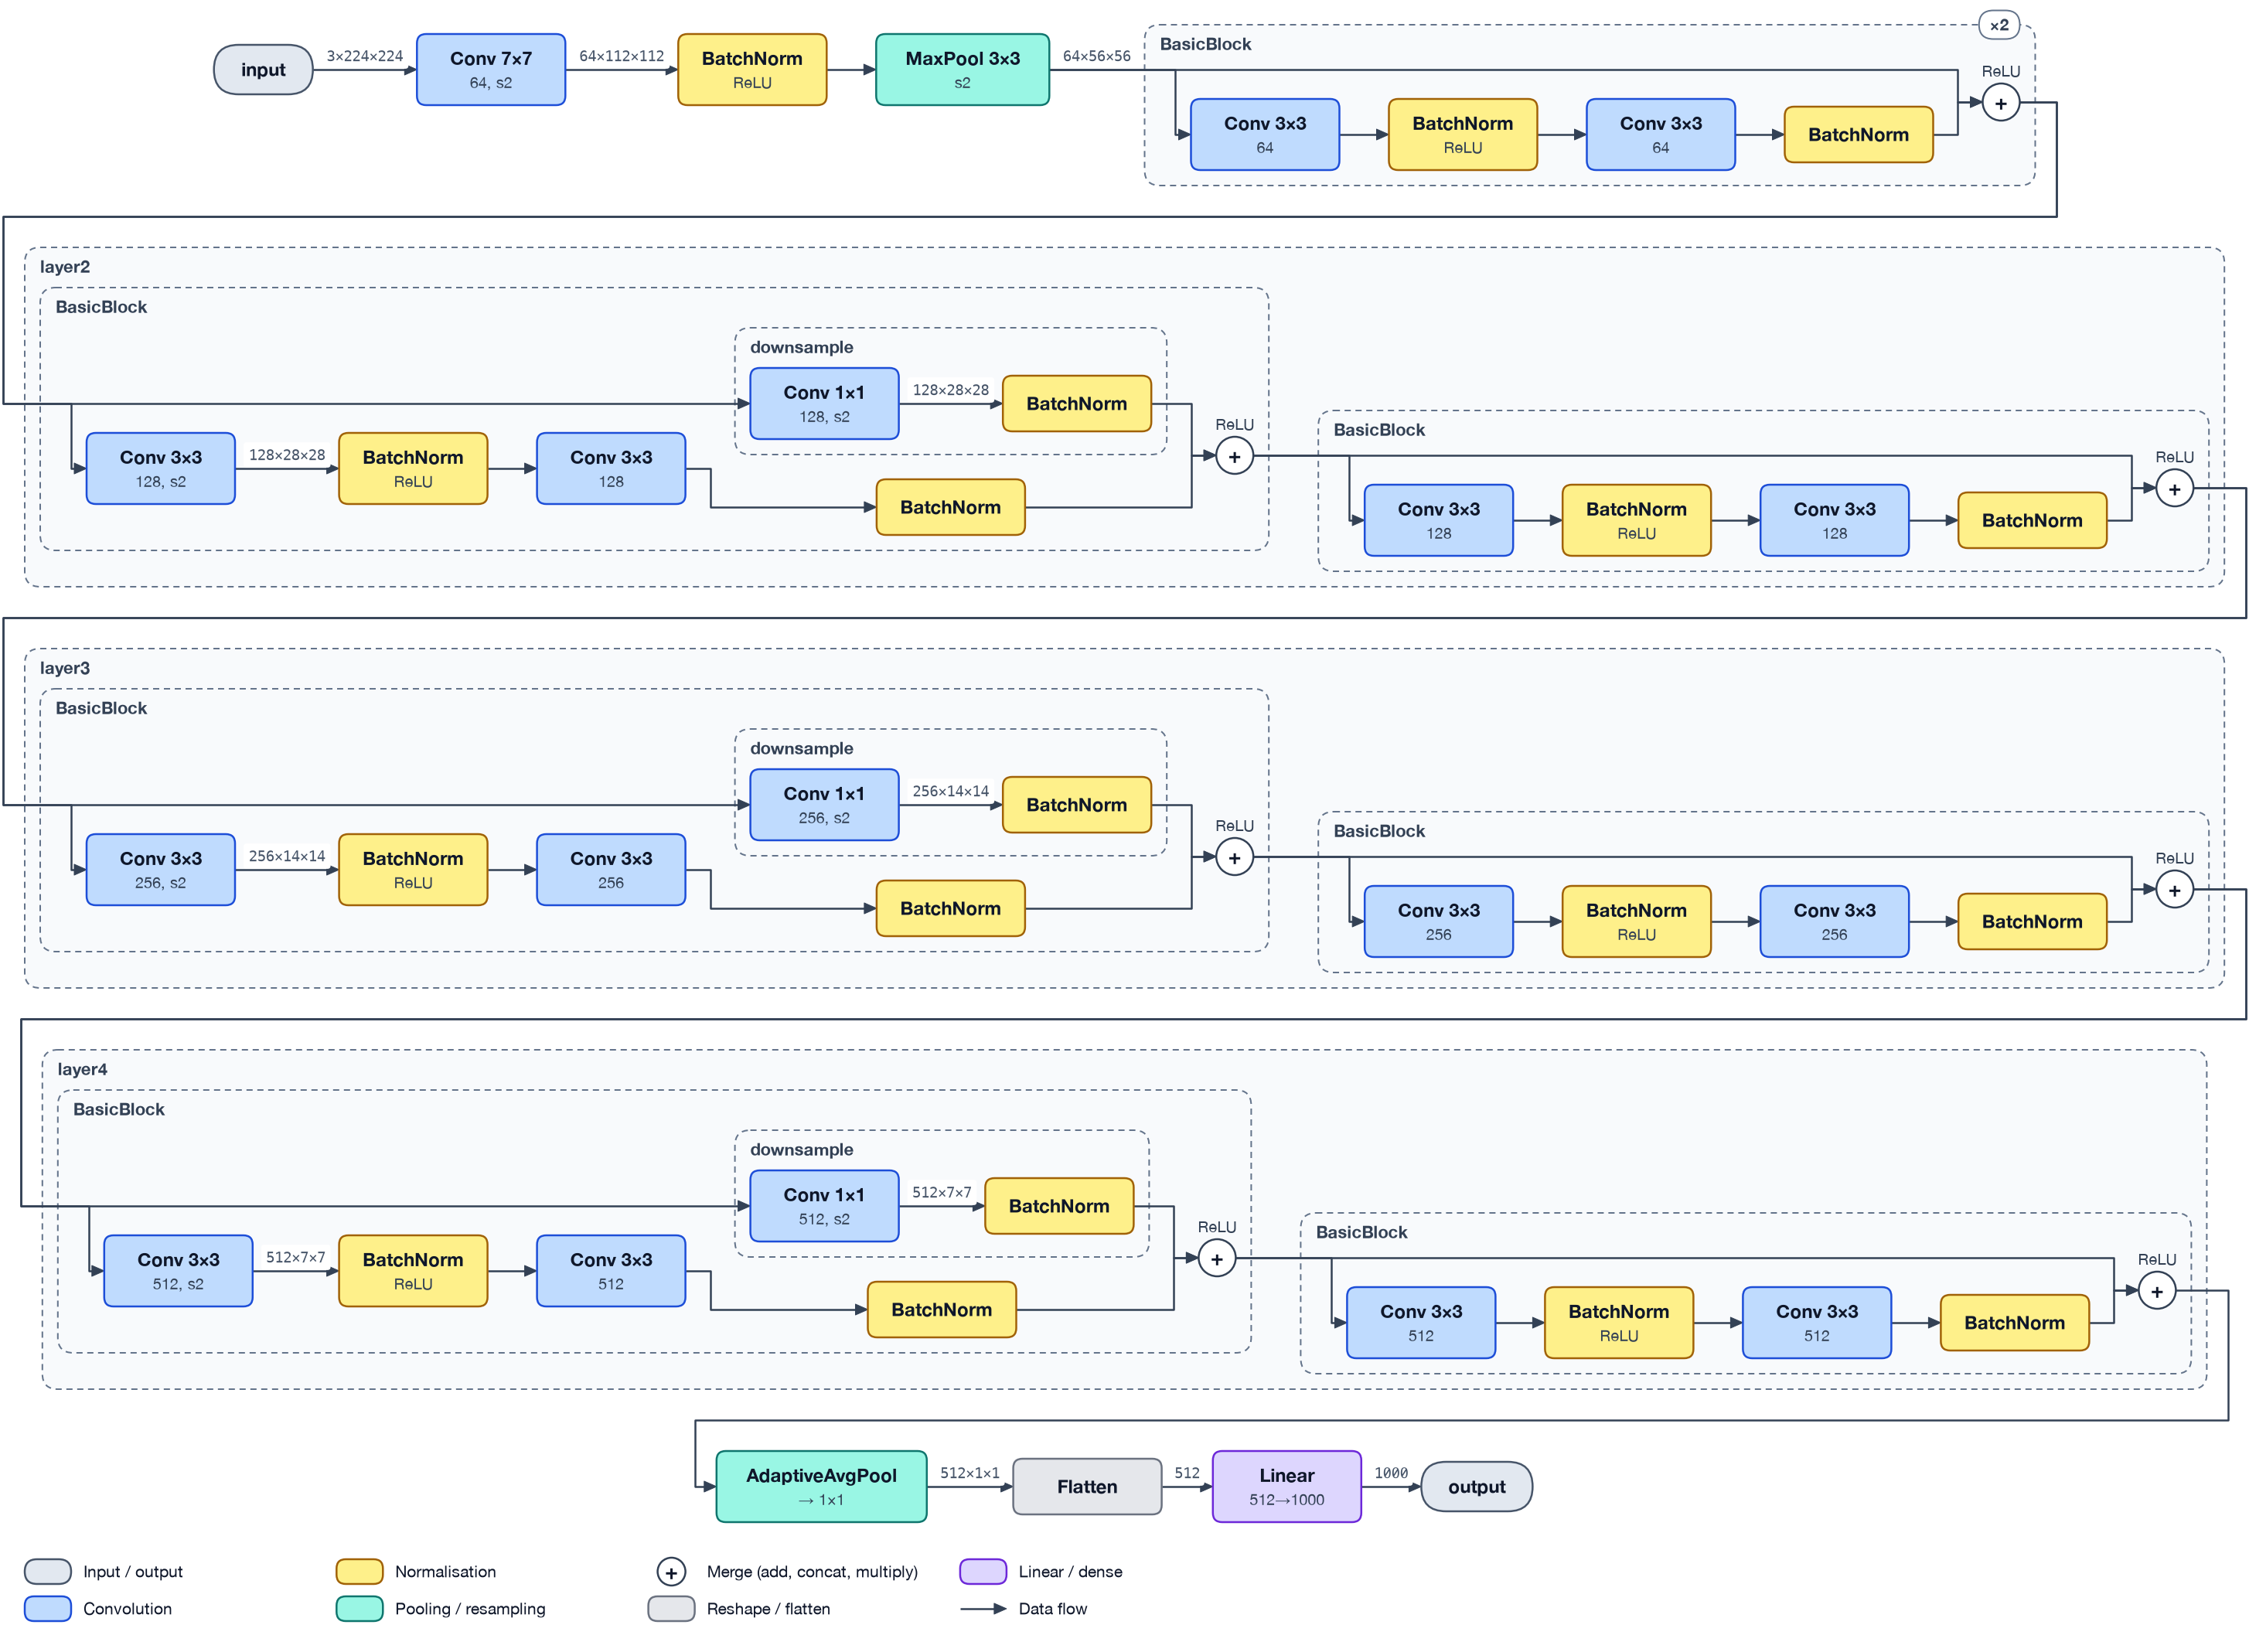

In [5]:
tg.draw(model, x, wrap_width=1800)

## Deeper ResNets

ResNet-34 has 3, 4, 6 and 3 blocks per stage. After the first block of a stage the others are
identical, so each run is drawn once, marked ×2, ×3, ×5: the figure is as large as ResNet-18's.

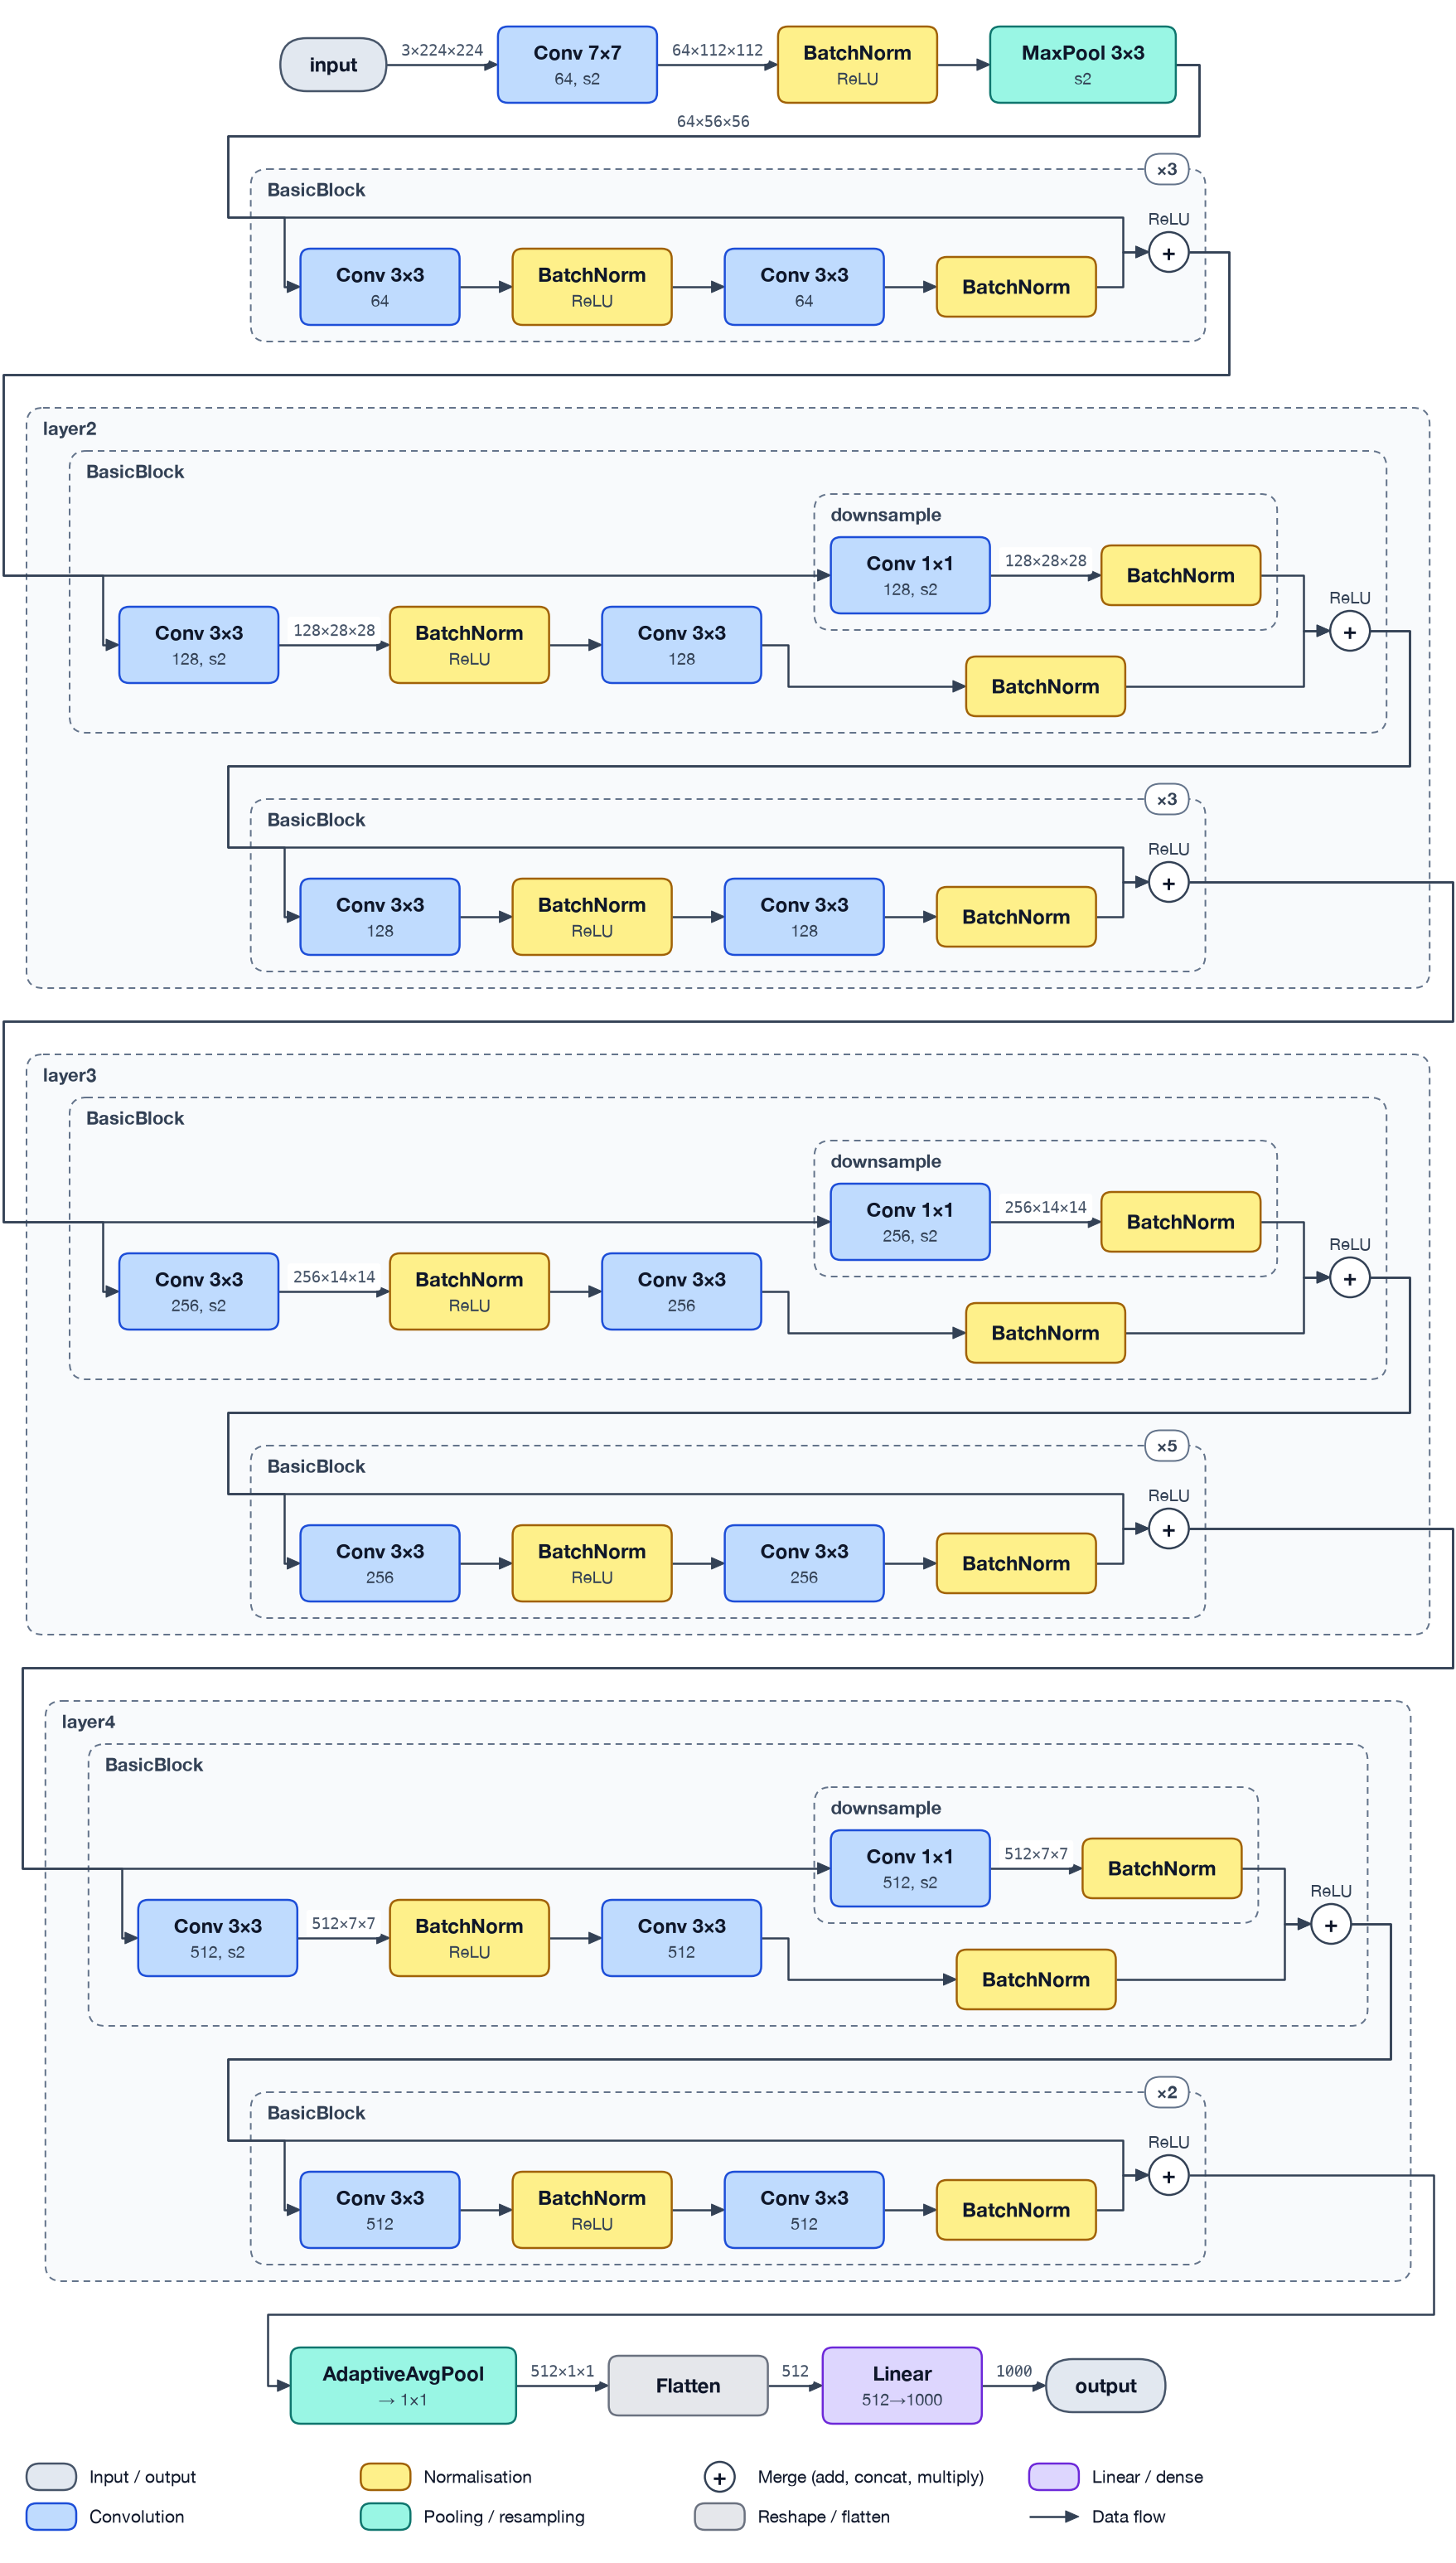

In [6]:
tg.draw(resnet34(), x)

ResNet-50 uses bottleneck blocks: a 1×1 convolution down to fewer channels, a 3×3 one, and a
1×1 back up to four times as many.

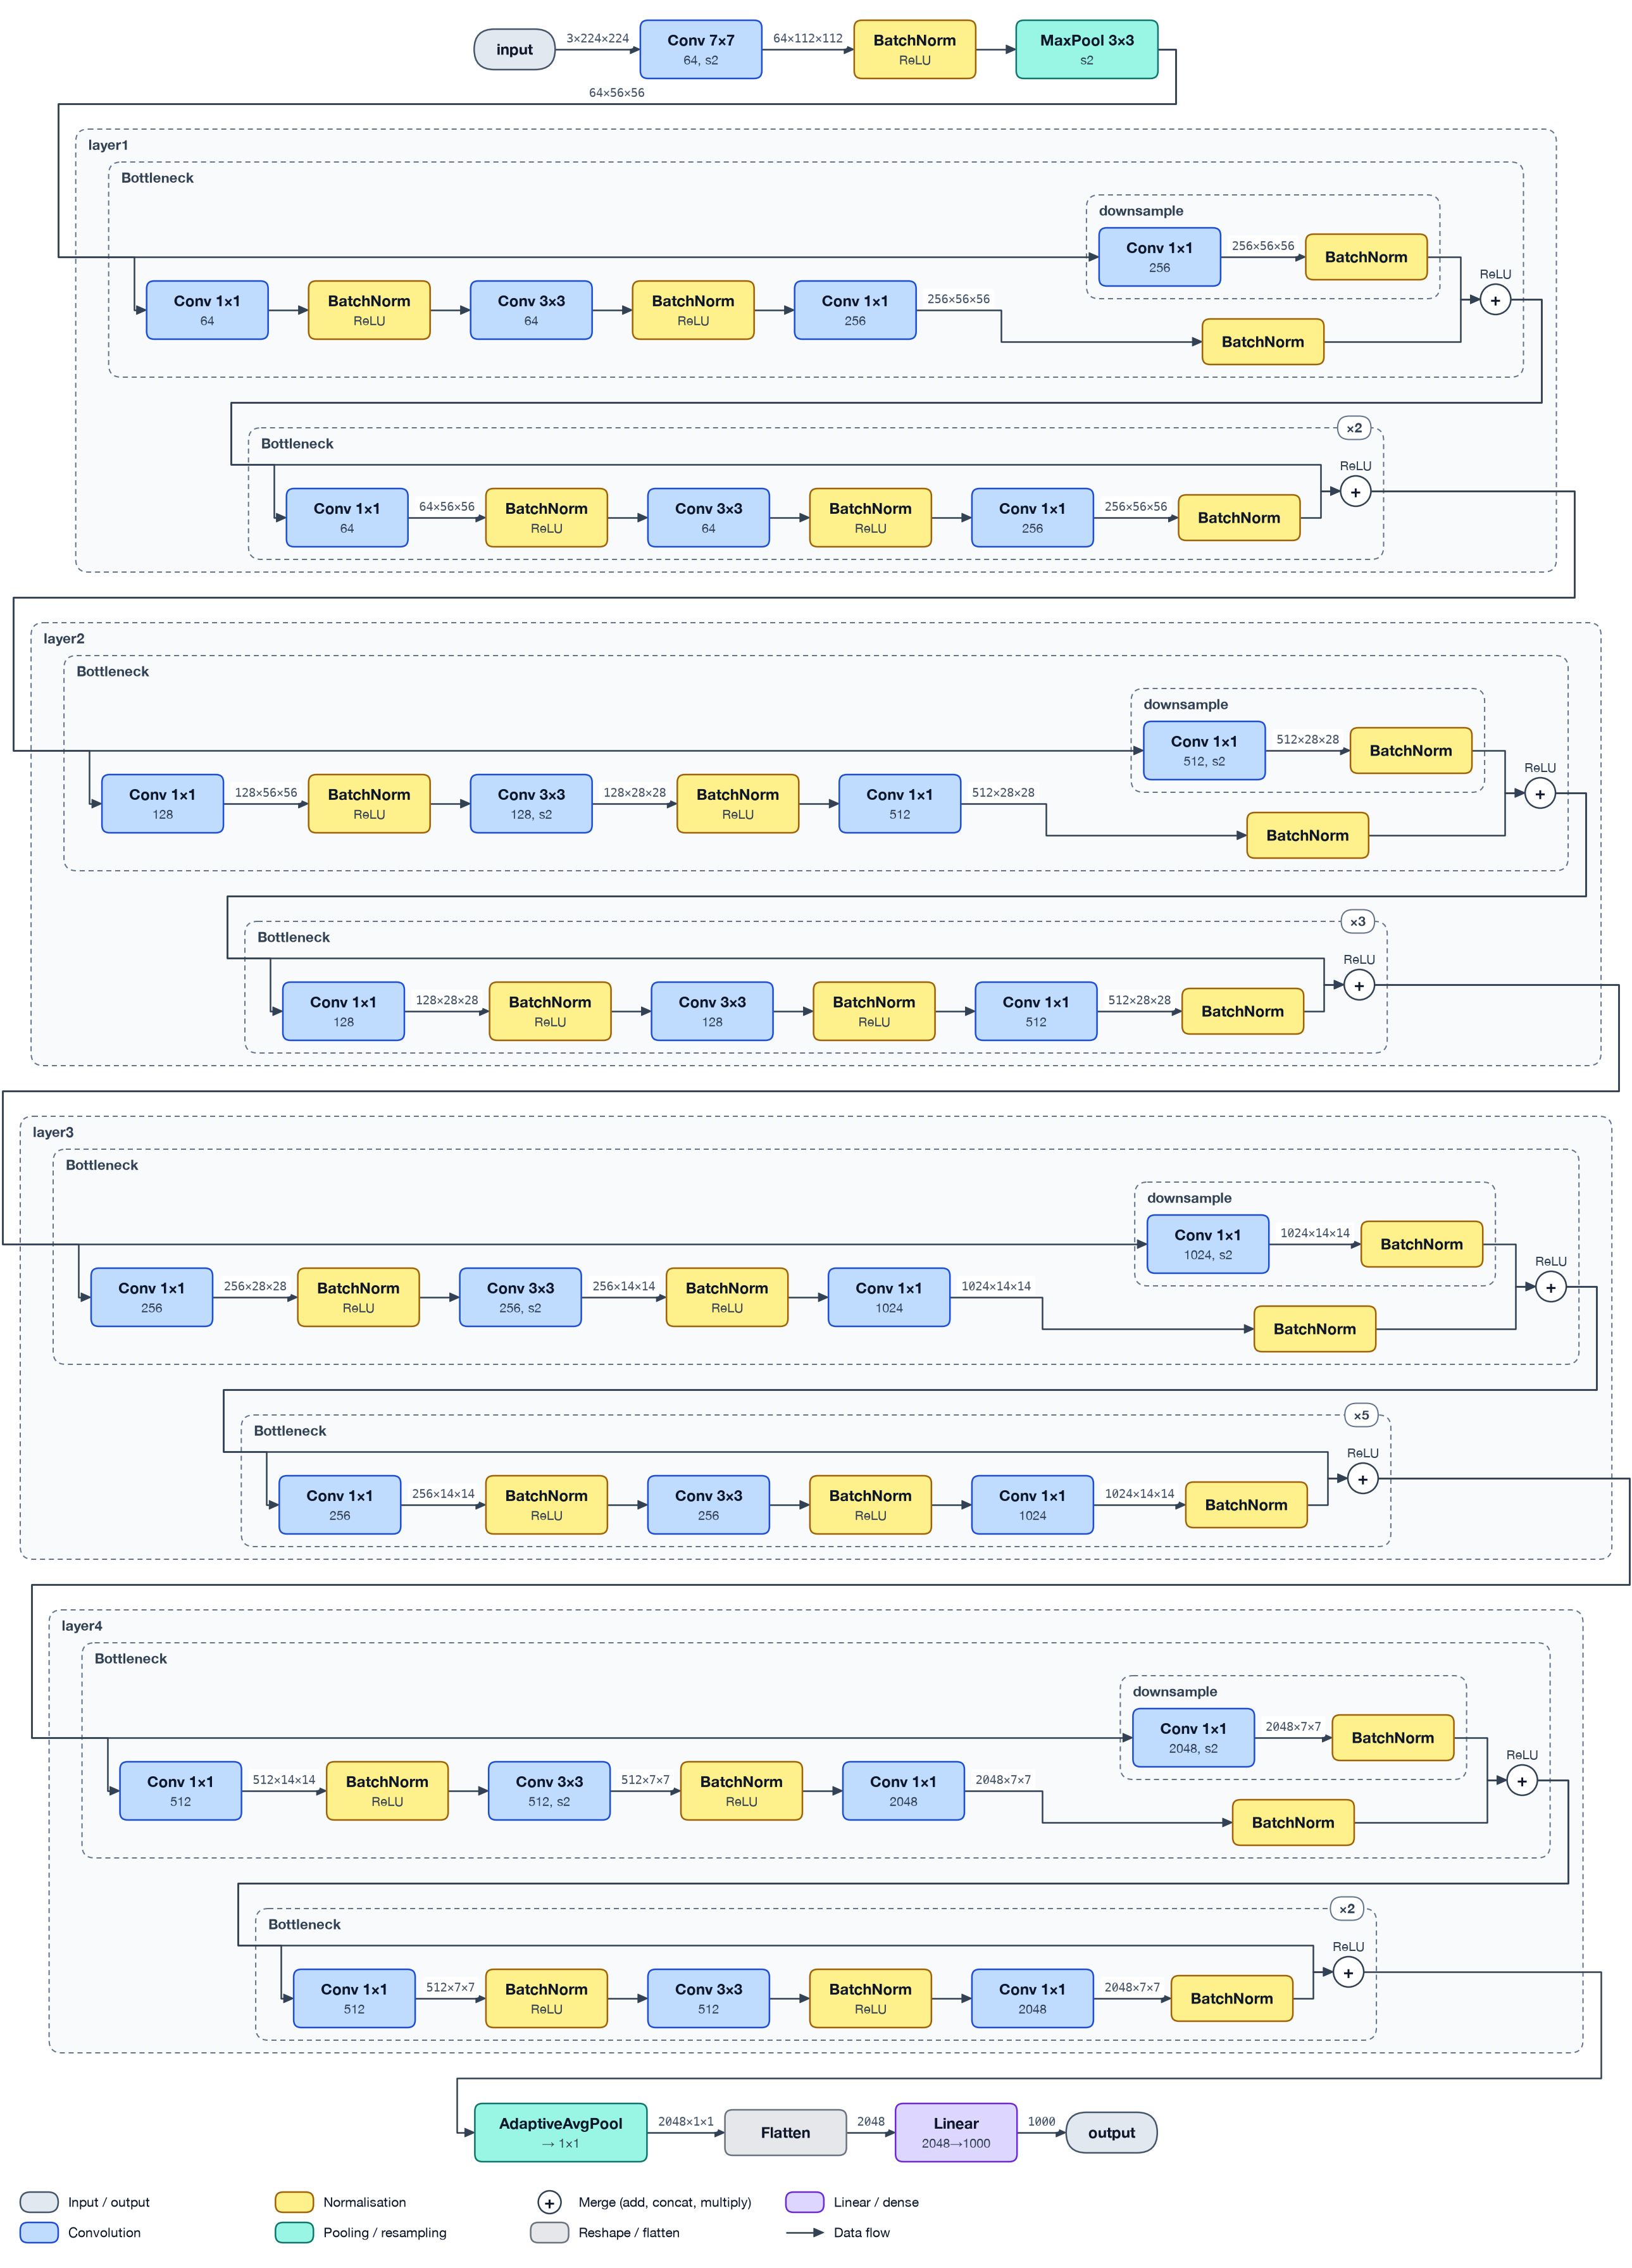

In [7]:
tg.draw(resnet50(), x)

## Views and styles

`view="volume"` draws every layer as the tensor it produces; `style="origami"` (upright cards)
and `style="origami-extended"` (flat cards, top → bottom) as for AlexNet.

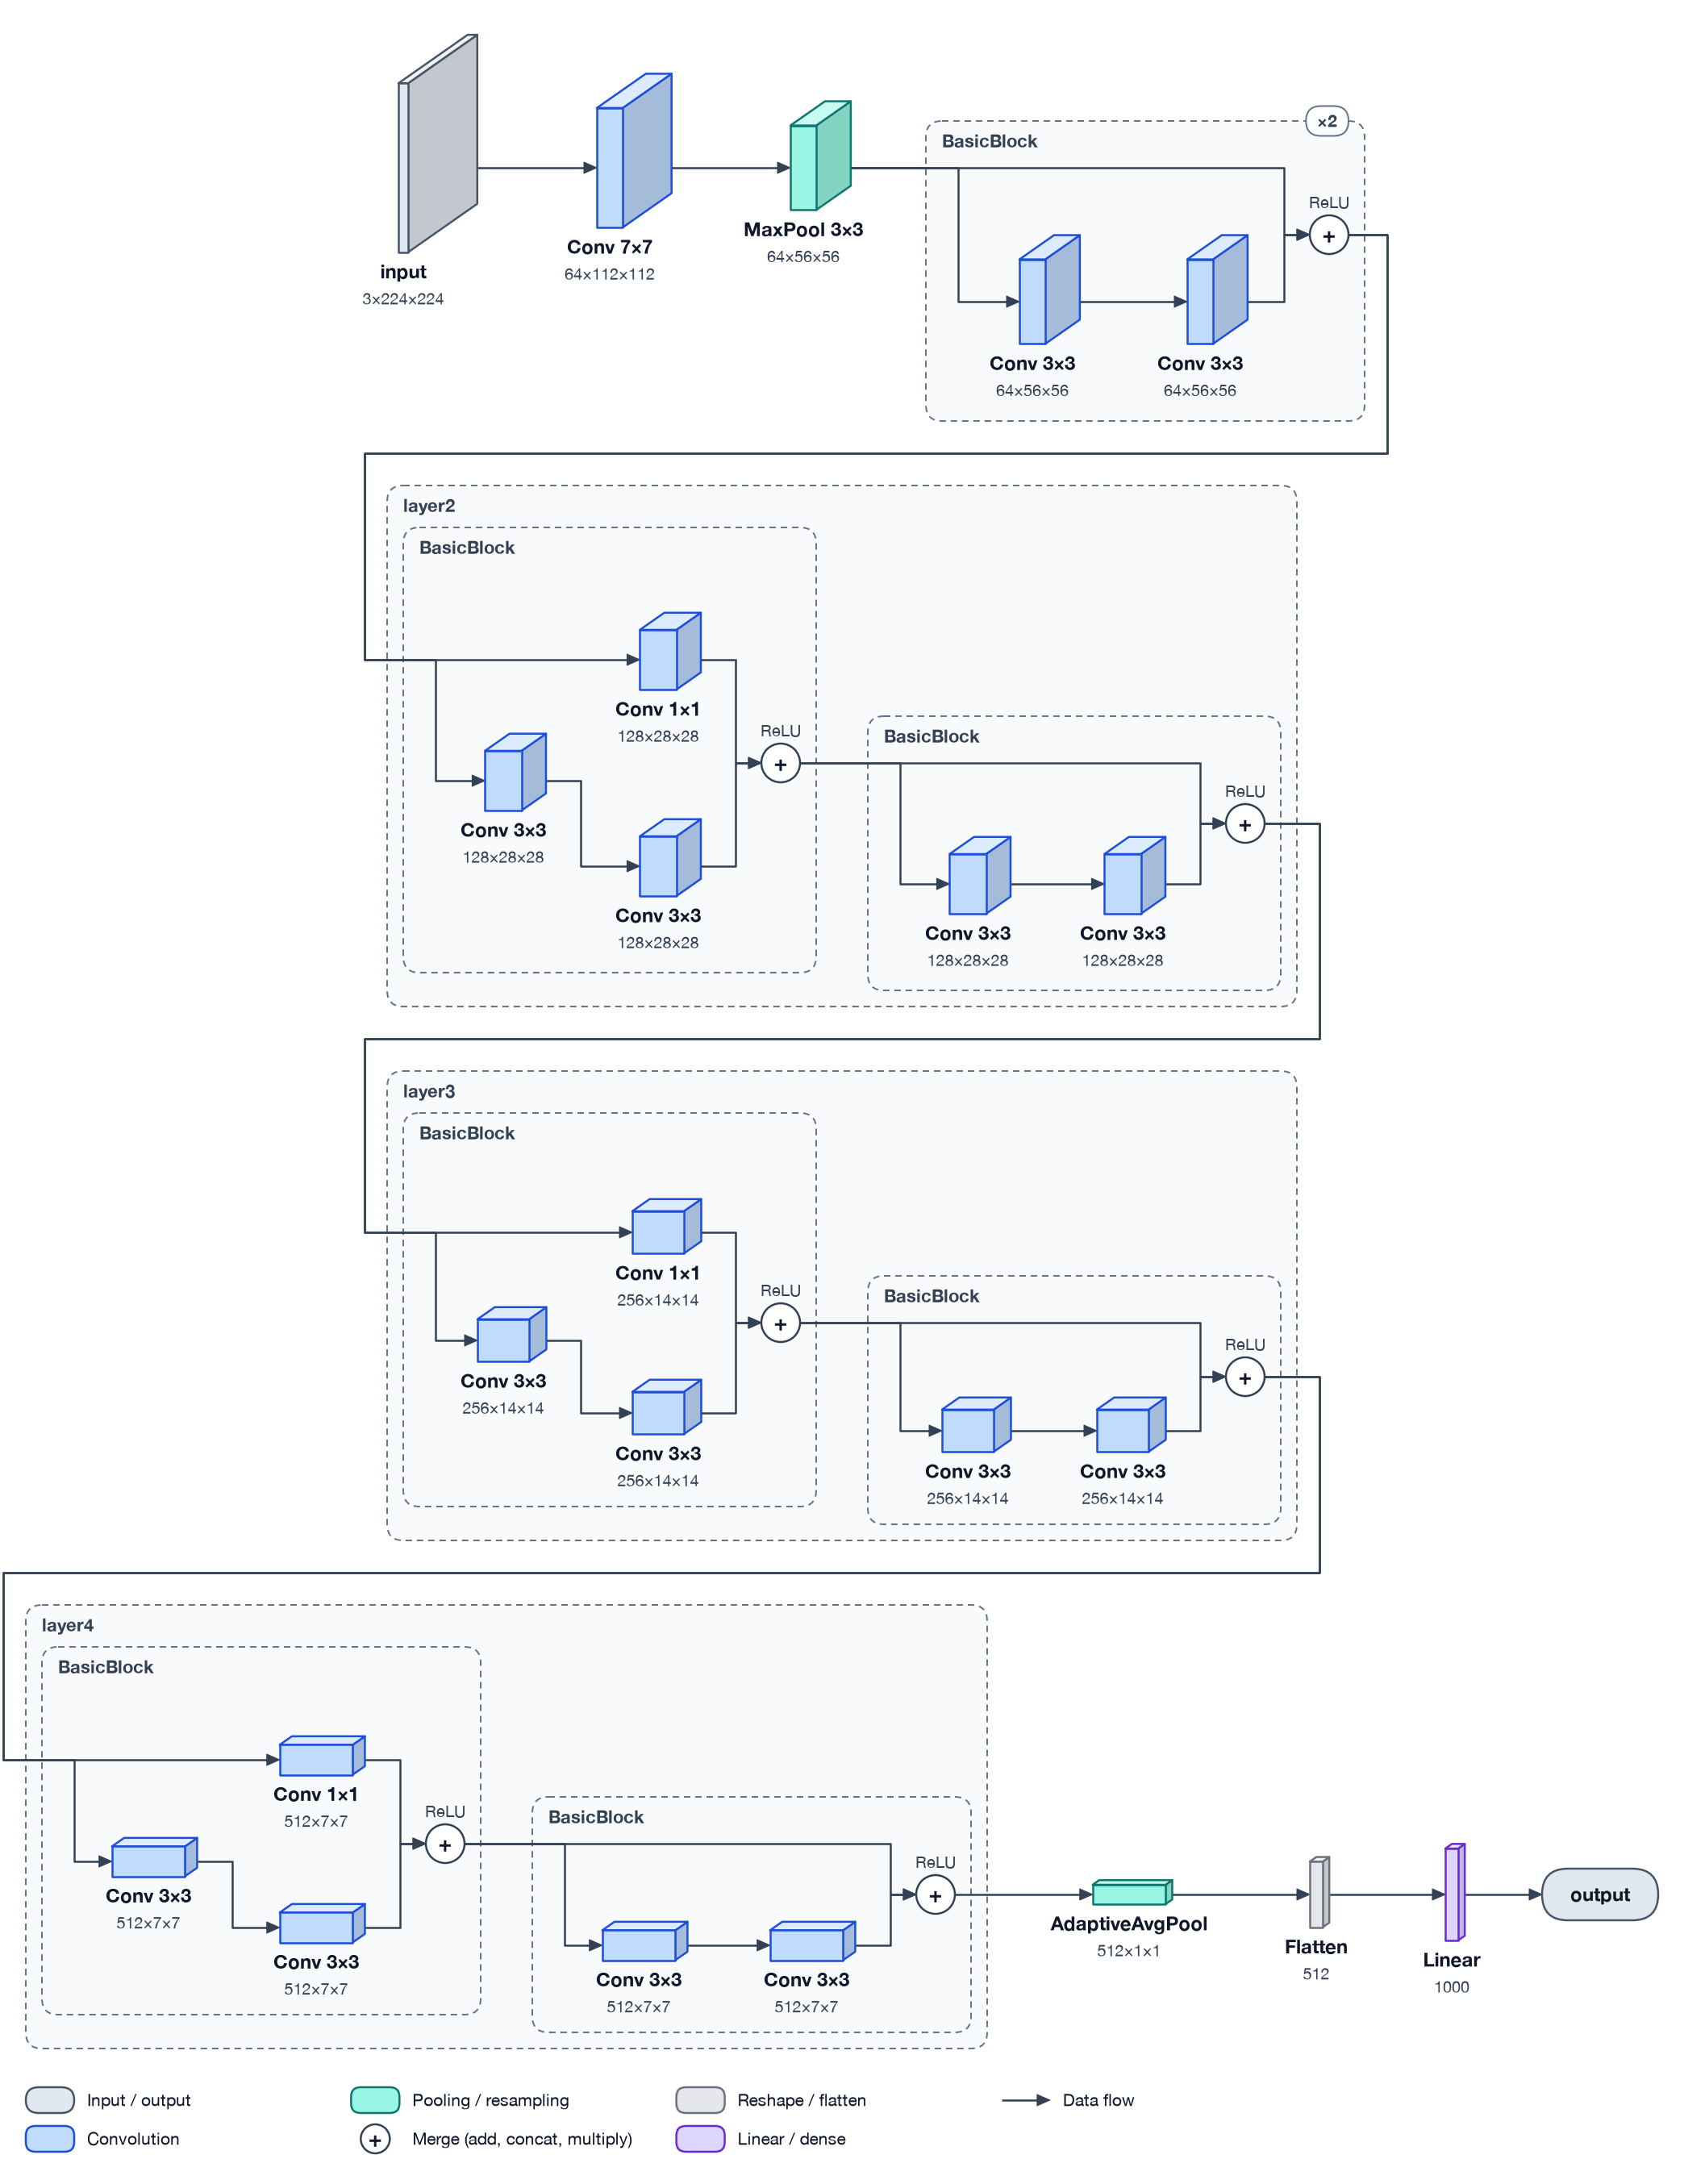

In [8]:
tg.draw(model, x, view="volume")

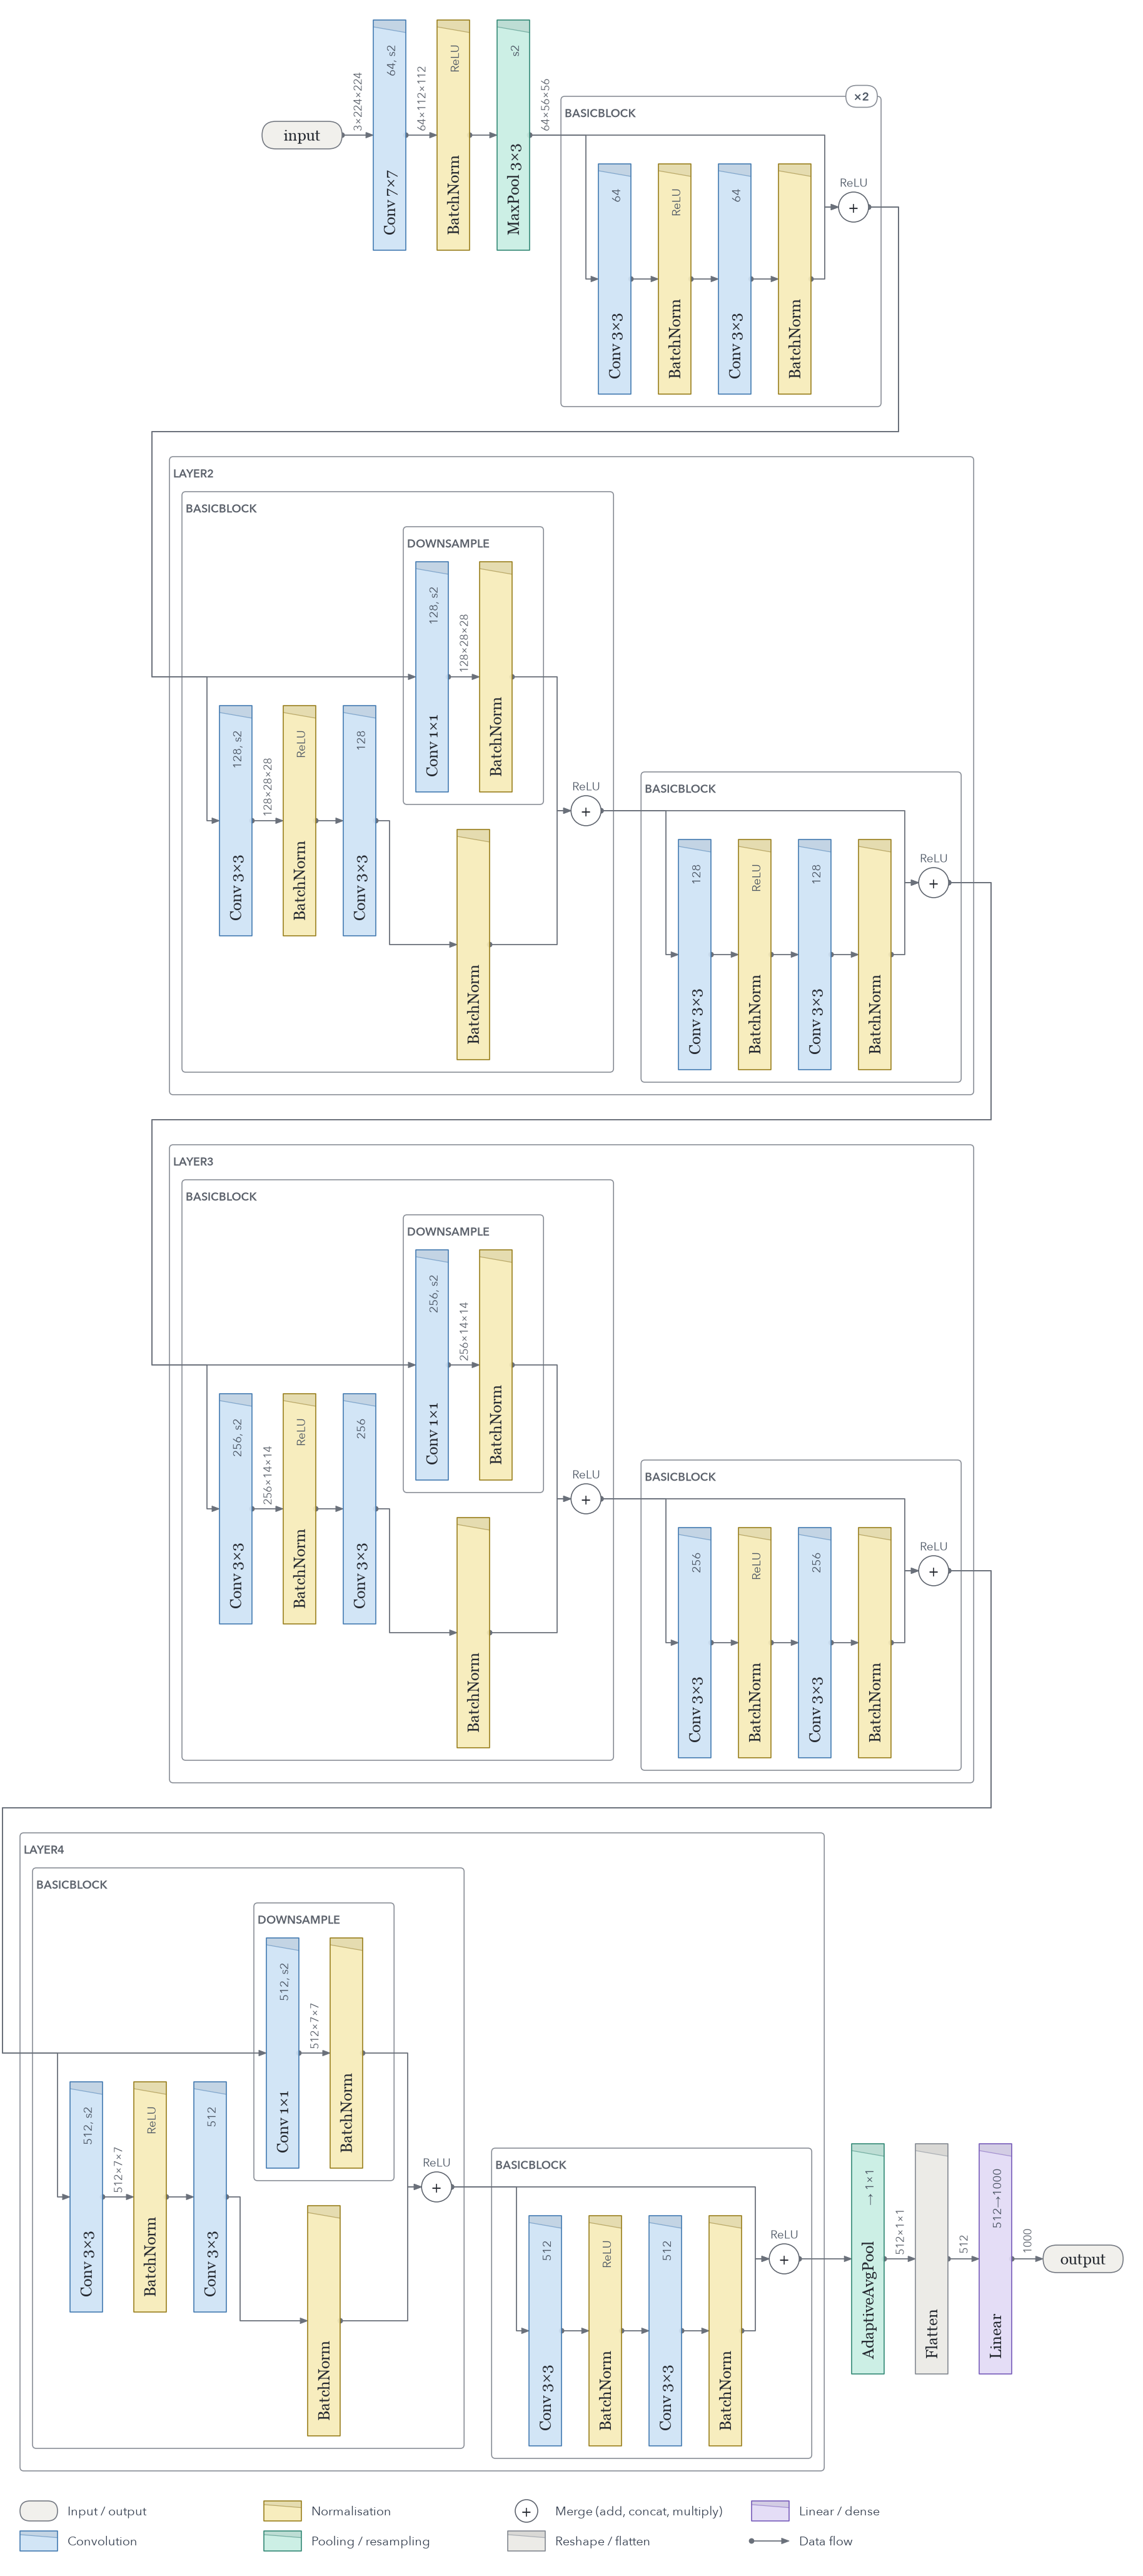

In [9]:
tg.draw(model, x, style="origami")

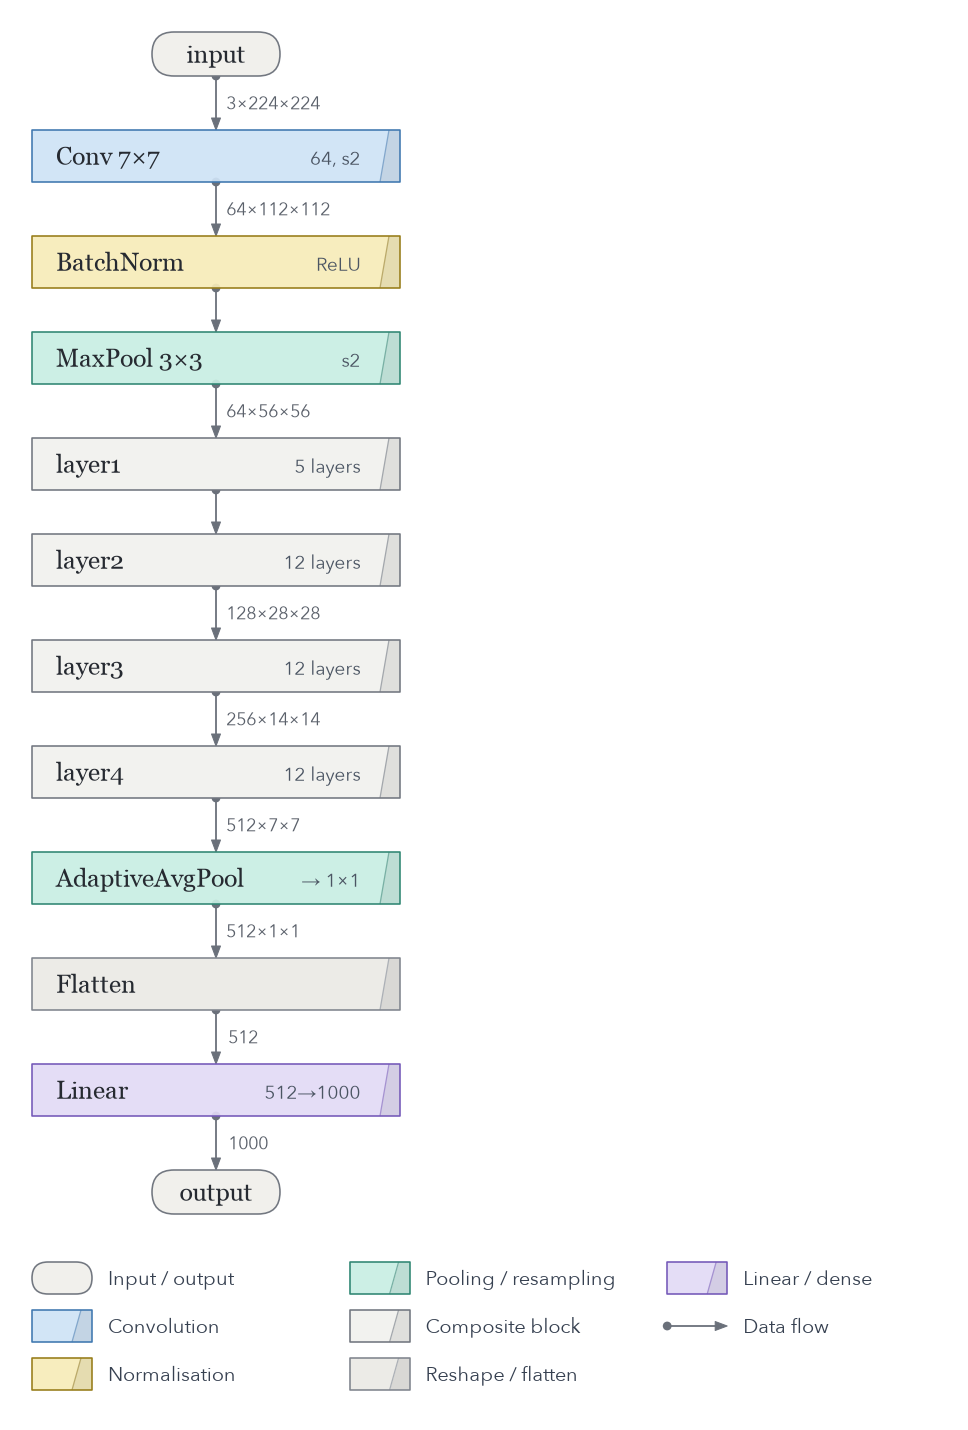

In [10]:
tg.draw(model, x, level="stages", style="origami-extended")

## Pretrained weights

The drawing does not depend on the weights, so the models above are untrained. The module
names match torchvision's, so its trained weights load directly, e.g. `model.load_state_dict(torch.load("resnet18-f37072fd.pth"))` with the file from
`torchvision.models.ResNet18_Weights.IMAGENET1K_V1.url`.